# ASPIRE versus the matrix product disentangler

Two many-body ground states, a 2D transverse-field Ising model and a Heisenberg ladder (snake-ordered onto a chain, N = 12), are prepared with ASPIRE and with the matrix product disentangler (MPD). Infidelity is $\varepsilon = 1-|\langle\psi|C|0\rangle|$ with the free layer of single-qubit rotations included, and only two-qubit gates are counted. Blue is the MPD and orange is ASPIRE.

In [1]:
using Pkg; Pkg.activate(@__DIR__)

In [2]:
using ASPIRE, Plots, Random
using ITensorMPS: siteinds, maxlinkdim

set_max_bond_dim!(64)
default(size = (820, 360), framestyle = :box, linewidth = 2, markersize = 5,
        legend = :topright, guidefontsize = 10, titlefontsize = 10, left_margin = 4Plots.mm,
        bottom_margin = 4Plots.mm)
const BLUE, ORANGE, GREY = "#1f77b4", "#ff7f0e", "#555555"

("#1f77b4", "#ff7f0e", "#555555")

Ground states by DMRG, with their total correlation and the certificate quantity Lambda.

In [3]:
tfim = tfim_snake_state(3, 4; J = 1.0, h = 2.0, nsweeps = 8, maxdim = [8, 16, 32], rng = MersenneTwister(1))
heis = heisenberg_snake_state(4, 3; nsweeps = 8, maxdim = [8, 16, 32], rng = MersenneTwister(1))
targets = ["TFIM 3x4, h = 2" => tfim, "Heisenberg 4x3" => heis]

for (name, psi) in targets
    println(rpad(name, 18), "N = ", length(psi), "   chi = ", maxlinkdim(psi),
            "   T = ", round(total_correlation(psi), digits = 3), " bits",
            "   Lambda = ", round(lambda_certificate(psi), digits = 3))
end

TFIM 3x4, h = 2   N = 12   chi = 25   T = 1.163 bits   Lambda = 0.151
Heisenberg 4x3    N = 12   chi = 32   T = 12.0 bits   Lambda = 6.0


The MPD is run for five staircase layers without optimisation. ASPIRE is stopped at the gate count of each MPD layer, selecting each layer by exact matching over the 32 best pairs.

In [4]:
aspire_config(gmax) = ASPIREConfig(threshold = 0.0, relative_threshold = 0.0, max_depth = 30,
                                   max_gates = gmax, batch_mode = :matching, shortlist = 32,
                                   cost_normalised = false)

function compare(psi; layers = 5)
    mpd = ran_iter_oall_curve(psi; Lmax = layers, sweeps = 0)
    budgets = mpd.gates[2:end]
    runs = [aspire(psi; config = aspire_config(g)) for g in budgets]
    eps0 = runs[1].product_frame_amplitude_infidelity[1]
    eps_mpd = [eps0; 1 .- sqrt.(clamp.(mpd.fid[2:end], 0, 1))]
    eps_asp = [eps0; [r.product_frame_amplitude_infidelity[end] for r in runs]]
    gates_asp = [0; [r.gates[end] for r in runs]]
    return (gates_mpd = mpd.gates, eps_mpd = eps_mpd, gates_asp = gates_asp, eps_asp = eps_asp, runs = runs)
end

results = [name => compare(psi) for (name, psi) in targets]
for (name, res) in results
    println(name)
    println("  gates (MPD)      ", res.gates_mpd)
    println("  gates (ASPIRE)   ", res.gates_asp)
    println("  eps   (MPD)      ", round.(res.eps_mpd, sigdigits = 3))
    println("  eps   (ASPIRE)   ", round.(res.eps_asp, sigdigits = 3))
    println("  eps_MPD / eps_ASPIRE ", round.(res.eps_mpd[2:end] ./ res.eps_asp[2:end], digits = 2))
end

TFIM 3x4, h = 2
  gates (MPD)      [0, 11, 22, 33, 44, 55]
  gates (ASPIRE)   [0, 11, 22, 33, 44, 55]
  eps   (MPD)      [0.0374, 0.00967, 0.0051, 0.00328, 0.00269, 0.00222]
  eps   (ASPIRE)   [0.0374, 0.0147, 0.00167, 0.000583, 0.000397, 0.000317]
  eps_MPD / eps_ASPIRE [0.66, 3.06, 5.63, 6.78, 7.0]
Heisenberg 4x3
  gates (MPD)      [0, 11, 22, 33, 44, 55]
  gates (ASPIRE)   [0, 11, 22, 33, 44, 55]
  eps   (MPD)      [0.69, 0.357, 0.184, 0.161, 0.142, 0.127]
  eps   (ASPIRE)   [0.69, 0.322, 0.166, 0.136, 0.0994, 0.0797]
  eps_MPD / eps_ASPIRE [1.11, 1.11, 1.19, 1.43, 1.6]


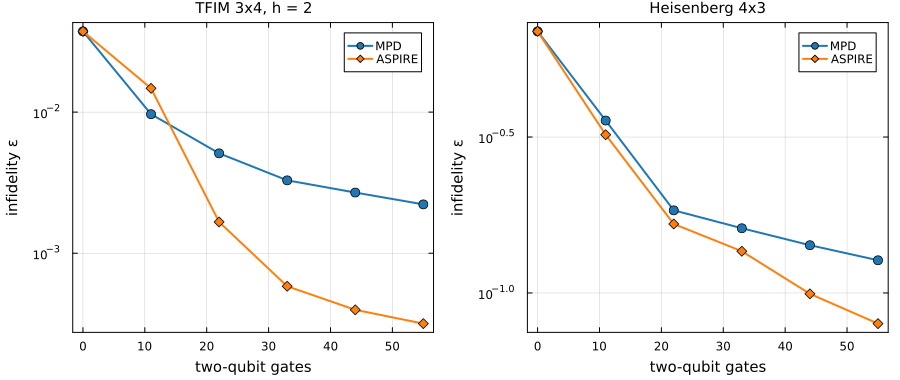

In [5]:
panels = map(results) do (name, res)
    plot(res.gates_mpd, res.eps_mpd; yscale = :log10, marker = :circle, color = BLUE, label = "MPD",
         xlabel = "two-qubit gates", ylabel = "infidelity ε", title = name)
    plot!(res.gates_asp, res.eps_asp; marker = :diamond, color = ORANGE, label = "ASPIRE")
end
plot(panels...; layout = (1, 2), size = (900, 380))

Along the longest ASPIRE run, the certified infidelity bound built from the largest single-site eigenvalues is compared with the actual infidelity. The actual value is also recomputed from the circuit that `prep_circuit_from_gate_log` builds from the gate log.

In [6]:
function certificate_trace(psi, run)
    bound = certified_infidelity_bound.(run.lambda)
    actual = run.product_frame_amplitude_infidelity
    circuit = prep_circuit_from_gate_log(run.gate_log, siteinds(psi))
    eps_circuit = 1 - sqrt(product_frame_squared_fidelity(psi, circuit))
    return (; bound, actual, eps_circuit)
end

traces = [name => certificate_trace(psi, res.runs[end]) for ((name, psi), (_, res)) in zip(targets, results)]
for ((name, tr), (_, res)) in zip(traces, results)
    run = res.runs[end]
    println(name)
    println("  gates              ", run.gates)
    println("  Lambda             ", round.(run.lambda, sigdigits = 3))
    println("  Lambda <= T/2      ", all(run.lambda .<= run.T ./ 2 .+ 1e-12))
    println("  bound >= actual    ", all(tr.bound .>= tr.actual .- 1e-12))
    println("  final eps from the gate log vs selector: ", round(tr.eps_circuit, sigdigits = 4), " vs ",
            round(tr.actual[end], sigdigits = 4))
end

TFIM 3x4, h = 2
  gates              [0, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 55]
  Lambda             [0.151, 0.101, 0.0599, 0.0337, 0.0111, 0.00688, 0.00478, 0.00355, 0.00323, 0.00275, 0.00254, 0.0023]
  Lambda <= T/2      true
  bound >= actual    true
  final eps from the gate log vs selector: 0.000317 vs 0.000317
Heisenberg 4x3
  gates              [0, 6, 12, 18, 24, 29, 34, 38, 43, 48, 52, 55]
  Lambda             [6.0, 2.39, 1.82, 1.38, 1.21, 1.08, 0.886, 0.761, 0.671, 0.625, 0.581, 0.552]
  Lambda <= T/2      true
  bound >= actual    true
  final eps from the gate log vs selector: 0.07974 vs 0.07974


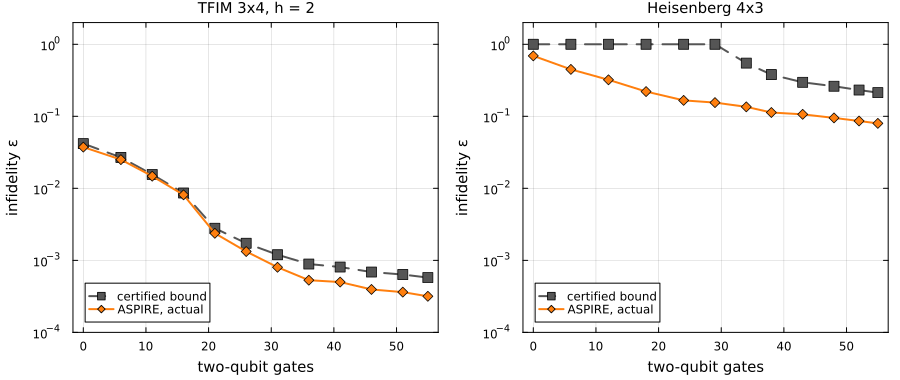

In [7]:
panels = map(zip(traces, results)) do ((name, tr), (_, res))
    g = res.runs[end].gates
    plot(g, tr.bound; yscale = :log10, ylims = (1e-4, 2), color = GREY, linestyle = :dash, marker = :square,
         label = "certified bound", xlabel = "two-qubit gates", ylabel = "infidelity ε", title = name, legend = :bottomleft)
    plot!(g, tr.actual; color = ORANGE, marker = :diamond, label = "ASPIRE, actual")
end
plot(panels...; layout = (1, 2), size = (900, 380))